# Training experiments: first model exploration

**EGN 6216 · AI Systems · Module 7 homework** · Mashoukur Rahman  
**Project:** AI-based land subsidence susceptibility mapping, Tulare-Corcoran study area (San Joaquin Valley)

This notebook follows the six steps of the assignment and moves the work from `playground.ipynb` into a dedicated experiment notebook. Step 7 (new in this version) adds LIME explanations of the trained forest and four checks on whether those explanations can be trusted. It is preparation for Milestone 4 (Section 7 of the project template).

**Sections:** Step 1 role of AI and candidates · Setup · Step 2 data · Step 3 first run (model configuration, training) · Step 4 evaluation · Step 5 errors and practical constraints · Step 6 one targeted change · leakage checks · **Step 7 explanations with LIME** · experiment results and notes.

**Evaluation rule.** The 967 labeled test cells (14 held-out 5 km blocks from `insar_label.ipynb`) are not scored and their labels are not used anywhere in this notebook; their predictor values appear only in two places that do not score anything (the groundwater value count and the timing of a whole-grid prediction). All scores below are validation scores from cross-validation over whole blocks of the 40 training blocks.

**To rerun:** open the notebook from the repository root so that `data/subsidence_dataset_processed.csv` (written by `insar_label.ipynb`) is found, then run all cells. Step 7 needs the `lime` package (`pip install lime==0.2.0.1`, which also installs scikit-image) and adds about one minute.

## Step 1: Role of AI and candidate approaches

**Role of AI.** The AI component is a classifier. Its input is one 500 m grid cell described by the conditions observed in 2016–2019 (land use, soil, terrain and groundwater), and its output is one of five susceptibility classes (very low to very high) for how much that cell sank over 2020–2024 according to InSAR, together with the class probabilities that I plan to use as the per-cell confidence. It produces a relative ranking to help prioritise monitoring, not a forecast of exact displacement.

**Candidates.**
- **Random Forest** (scikit-learn): selected first.
- **Gradient-boosted trees** (`HistGradientBoostingClassifier`): the next candidate if the forest turns out weak.
- **Logistic regression on two indicators** (groundwater decline rate and clay %, the simple-indicator baseline from 1.5): run here only as a reference point.
- **Persistence baseline** (1.5): not run. It needs each cell's 2016–2019 InSAR trend, which is not in my processed table; building it means extracting the pre-2020 series from the 5 GB InSAR file.
- **CNN / U-Net**: stretch goal in the project plan, not attempted.

**Why Random Forest first.** The data is a table of about 2,600 labeled development cells with a mix of numeric and categorical columns. A forest needs no feature scaling, trains in seconds on a CPU (my target in 2.1 is under 30 minutes), returns class probabilities that can serve as confidence, gives feature importances, and is the approach in my Milestone 2 plan.

**Parts of the workflow that are not AI.** Reprojection to EPSG:5070 and the 500 m grid; filling each cell's groundwater values from its nearest well; the per-point InSAR trend and the per-cell median; the four class cut points (fixed from the training cells in `insar_label.ipynb`); the 5 km block split; the `soil_missing` flag; and, later, the confidence thresholds, the three-state symbology and the GeoTIFF export. I test the class cut points below (Section 2b).

**Stage explored first:** the classification stage (task 3 in 2.1).

## Setup

In [1]:
import os, sys, time, json, hashlib, platform, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, precision_recall_fscore_support

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

SEED = 42                      # one seed for the CV folds and the Random Forest (also used for the split in insar_label.ipynb)
CLASSES = ["very_low", "low", "moderate", "high", "very_high"]
CLASS_ID = {c: i for i, c in enumerate(CLASSES)}

print("python", sys.version.split()[0], "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("machine:", platform.platform(), "| logical CPUs:", os.cpu_count())

python 3.12.15 | scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.5.4
machine: Windows-11-10.0.26100-SP0 | logical CPUs: 32


## Step 2: Load and inspect the data

I load the processed table from Milestone 3, check its checksum against `label_build_log.json`, and keep only the labeled cells of the training blocks as development data. Everything that learns from data (imputer, encoder, forest) is fitted inside each cross-validation fold on that fold's training cells only.

In [2]:
DATA = next(p for p in ["data/subsidence_dataset_processed.csv", "../data/subsidence_dataset_processed.csv"] if os.path.exists(p))
EXPECTED_SHA256 = "ad033f34e110042e193ef9135dcae13e5905e9a487d2b881265aa53dc35cbd50"   # output_csv.sha256 in data/label_build_log.json

with open(DATA, "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()
print("file:", DATA)
print("sha256:", sha)
print("matches the checksum in label_build_log.json:", sha == EXPECTED_SHA256)

df_all = pd.read_csv(DATA)                       # all 5,192 cells (predictors only are used below, except the training labels)
labeled = df_all["susceptibility_class"].notna()
print("\ncells:", len(df_all), "| columns:", df_all.shape[1])
print("labeled:", int(labeled.sum()), "| no label (no usable InSAR point):", int((~labeled).sum()))
print("labeled cells by split:", df_all.loc[labeled, "split"].value_counts().to_dict())

# Development data = labeled cells of the 40 training blocks. The 967 labeled test cells are set aside here
# and never touched again in this notebook.
dev = df_all[labeled & (df_all["split"] == "train")].reset_index(drop=True)
N_TEST_UNUSED = int((labeled & (df_all["split"] == "test")).sum())
print("\ndevelopment cells:", len(dev), "in", dev["block_id"].nunique(), "blocks | test cells left unused:", N_TEST_UNUSED)

y = dev["susceptibility_class"].map(CLASS_ID).to_numpy()
groups = dev["block_id"].to_numpy()

file: data/subsidence_dataset_processed.csv
sha256: ad033f34e110042e193ef9135dcae13e5905e9a487d2b881265aa53dc35cbd50
matches the checksum in label_build_log.json: True

cells: 5192 | columns: 37
labeled: 3539 | no label (no usable InSAR point): 1653
labeled cells by split: {'train': 2572, 'test': 967}

development cells: 2572 in 40 blocks | test cells left unused: 967


In [3]:
# class balance of the development cells (cut points were computed from these cells, so they are balanced by construction)
bal = dev["susceptibility_class"].value_counts().reindex(CLASSES)
print("class counts (development cells):")
print(pd.DataFrame({"cells": bal, "share_%": (100 * bal / len(dev)).round(1)}).T.to_string())

print("\ncells per block: min", dev.groupby("block_id").size().min(), "| median", int(dev.groupby("block_id").size().median()),
      "| max", dev.groupby("block_id").size().max())

# missing values among the development cells
miss = dev.isna().sum()
miss = miss[miss > 0].drop(["insar_disp_window", "subsidence"], errors="ignore")
print("\nmissing values among development cells (columns with any):")
print(pd.DataFrame({"missing": miss, "share_%": (100 * miss / len(dev)).round(1)}).to_string())
print("\nlabel support: insar_n_points median", int(dev["insar_n_points"].median()),
      "| cells resting on 1 point:", int((dev["insar_n_points"] == 1).sum()),
      "| on fewer than 3:", int((dev["insar_n_points"] < 3).sum()))

class counts (development cells):
susceptibility_class  very_low    low  moderate   high  very_high
cells                    515.0  514.0     514.0  514.0      515.0
share_%                   20.0   20.0      20.0   20.0       20.0

cells per block: min 10 | median 66 | max 95

missing values among development cells (columns with any):
                          missing  share_%
mukey                         113      4.4
drainagecl                    202      7.9
hydgrp                        125      4.9
taxclname                     202      7.9
clay_pct                      202      7.9
sand_pct                      202      7.9
silt_pct                      202      7.9
organic_matter_pct            202      7.9
ksat_um_per_s                 202      7.9
available_water_capacity      202      7.9

label support: insar_n_points median 6 | cells resting on 1 point: 343 | on fewer than 3: 620


**What I filled, dropped or left unchanged.**
- **Soil gaps (filled, inside each fold).** 202 of the 2,572 development cells (7.9%) have no soil properties (418 of the 5,192 grid cells, 8.1%), and 125 (4.9%) have no hydrologic group. Numeric gaps are filled with the median and categorical gaps with the most frequent value, both learned from the training cells of each fold only. The `soil_missing` flag stays in as an input so the model can tell which cells were filled.
- **Dropped:** nothing from the development data. The 1,653 cells with no label were already left out in Milestone 3 (no usable InSAR point).
- **Left unchanged:** all raw values (no clipping or scaling; a forest does not need it), the label, and the class cut points as built in `insar_label.ipynb`. `mukey` has 113 gaps but is an identifier and is not used.
- **Class balance:** 20% per class in the development cells by construction.
- **Label support:** the median label rests on 6 InSAR points; 343 development cells rest on a single point and 620 on fewer than three.

In [4]:
NUM = ["n_years_cropped", "n_years_fallow", "is_perennial_crop", "land_use_changed",
       "clay_pct", "sand_pct", "silt_pct", "organic_matter_pct", "ksat_um_per_s", "available_water_capacity",
       "elevation_m", "slope_deg",
       "gw_decline_m_per_yr_2016_2019", "gw_mean_depth_m", "gw_latest_depth_m", "gw_depth_std_m", "gw_n_measurements",
       "dist_to_nearest_well_m", "soil_missing"]
CAT = ["drainagecl", "hydgrp", "taxclname", "land_use_name_last_year"]
FEATURES = NUM + CAT

EXCLUDED = {
    "susceptibility_class, subsidence, insar_disp_window": "the label itself",
    "insar_n_points": "describes the label (how many InSAR points it rests on); not known for a new cell",
    "block_id, split": "bookkeeping from the split",
    "grid_id, mukey": "identifiers",
    "longitude, latitude": "location; I keep them out so the model has to use conditions, not memorise places (blocks are held out)",
    "cdl_code_2016 ... cdl_code_2019": "nominal crop codes; the derived years-cropped / fallow / perennial / changed fields and the last-year crop name carry the same information",
}
forbidden = {"susceptibility_class", "subsidence", "insar_disp_window", "insar_n_points", "block_id", "split",
             "grid_id", "mukey", "longitude", "latitude"}
assert not (set(FEATURES) & forbidden), "a label-derived or identifier column is in the feature list"
print(len(NUM), "numeric +", len(CAT), "categorical =", len(FEATURES), "features used")
print("\nnot used as features:")
for k, v in EXCLUDED.items():
    print(f"  {k:48s} {v}")

19 numeric + 4 categorical = 23 features used

not used as features:
  susceptibility_class, subsidence, insar_disp_window the label itself
  insar_n_points                                   describes the label (how many InSAR points it rests on); not known for a new cell
  block_id, split                                  bookkeeping from the split
  grid_id, mukey                                   identifiers
  longitude, latitude                              location; I keep them out so the model has to use conditions, not memorise places (blocks are held out)
  cdl_code_2016 ... cdl_code_2019                  nominal crop codes; the derived years-cropped / fallow / perennial / changed fields and the last-year crop name carry the same information


In [5]:
# data check found while preparing the inputs: how many different groundwater values are there?
gw_cols = ["gw_decline_m_per_yr_2016_2019", "gw_mean_depth_m", "gw_latest_depth_m", "gw_depth_std_m", "gw_n_measurements"]
print("distinct values over all", len(df_all), "cells:")
print(df_all[gw_cols + ["dist_to_nearest_well_m"]].nunique().to_string())
wells = (df_all.groupby("gw_mean_depth_m")
         .agg(cells=("grid_id", "size"), decline_m_per_yr=("gw_decline_m_per_yr_2016_2019", "first"),
              n_measurements=("gw_n_measurements", "first"),
              nearest_km_min=("dist_to_nearest_well_m", lambda s: s.min() / 1000),
              nearest_km_max=("dist_to_nearest_well_m", lambda s: s.max() / 1000))
         .round(2).sort_values("cells", ascending=False))
wells["share_%"] = (100 * wells["cells"] / len(df_all)).round(1)
print("\ncells grouped by the well they were filled from:")
print(wells.to_string())

distinct values over all 5192 cells:
gw_decline_m_per_yr_2016_2019       4
gw_mean_depth_m                     4
gw_latest_depth_m                   4
gw_depth_std_m                      4
gw_n_measurements                   3
dist_to_nearest_well_m           4813

cells grouped by the well they were filled from:
                 cells  decline_m_per_yr  n_measurements  nearest_km_min  nearest_km_max  share_%
gw_mean_depth_m                                                                                  
60.514992         4718              1.51               5           17.19           52.38     90.9
55.054500          176             -6.97               8           23.68           42.80      3.4
75.552300          159             -0.81               8           24.35           45.88      3.1
34.538920          139             -2.93               6           22.20           39.06      2.7


**Finding: the groundwater inputs take only four distinct values.** 4,718 of the 5,192 cells (90.9%) were filled from one and the same well (decline +1.51 m/yr, mean depth 60.5 m, 5 measurements), and the other three wells supply 139 to 176 cells each. So the five source-well groundwater columns work as a four-way region tag, and the only groundwater-related column that varies from cell to cell is `dist_to_nearest_well_m` (4,813 distinct values), which is a distance and so can only act as a coarse position stand-in. Section 6.4 reported the range of that distance but not this. I have not yet checked in `build_dataset.py` why only four wells ended up supplying values (the 300-well cap, the 2016–2019 date filter or a measurement-count filter are the places to look).

I keep the inputs as they are for Run 1, because this homework is about the first working version and changing inputs would mix with the targeted change in Step 6. The consequence for this experiment is that the model has almost no usable groundwater signal, which is the physical driver in my problem statement. Fixing it is the first item under next steps.

### 2b. Test of a non-AI stage: the class cut points

The labels come from fixed cut points on the displacement, so I re-apply them to the displacement of every development cell, check that they give back the stored classes, and try boundary and invalid inputs.

In [6]:
# Non-AI stage test: the class labels come from fixed cut points on the displacement (computed from the training cells
# in insar_label.ipynb). Re-apply them to the displacement and check that they reproduce the stored classes, then
# try boundary and invalid inputs.
CUTS = [-91.24081529480138, -20.95931510513884, 268.0284192680018, 654.5324537705515]   # cutpoints_from_train_only in label_build_log.json

def classify(displacement):
    """class index 0..4 for a displacement (positive = sinking); -1 for a missing / non-finite value"""
    d = np.asarray(displacement, dtype=float)
    k = np.searchsorted(CUTS, d, side="left")
    return np.where(np.isfinite(d), k, -1)

recomputed = classify(dev["subsidence"])
print("stored classes reproduced from the displacement:", int((recomputed == y).sum()), "of", len(y))

tests = {"just below first cut": CUTS[0] - 1e-6, "exactly on first cut": CUTS[0], "just above last cut": CUTS[3] + 1e-6,
         "0 (no displacement)": 0.0, "very large sinking": 1e6, "very large rise": -1e6, "NaN (no label)": np.nan, "inf": np.inf}
print("\nboundary and invalid inputs ->", {k: int(classify(v)) for k, v in tests.items()})
assert classify(np.nan) == -1 and classify(np.inf) == -1 and classify(-1e6) == 0 and classify(1e6) == 4

stored classes reproduced from the displacement: 2572 of 2572

boundary and invalid inputs -> {'just below first cut': 0, 'exactly on first cut': 0, 'just above last cut': 4, '0 (no displacement)': 2, 'very large sinking': 4, 'very large rise': 0, 'NaN (no label)': -1, 'inf': -1}


### 2c. Development split used for all runs

All runs use the same validation scheme: 5-fold cross-validation over whole 5 km blocks (`StratifiedGroupKFold`, grouped by `block_id`), inside the 40 training blocks. This follows the block logic of Section 6.5, because neighbouring 500 m cells are strongly correlated.

In [7]:
# Development evaluation: 5-fold CV over whole 5 km blocks, using only the training blocks.
# Every development cell is predicted once, by a model that never saw its block, so the scores below are
# validation scores, not test scores.
def make_cv(seed):
    return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)

X = dev[FEATURES]
for k, (tr_idx, va_idx) in enumerate(make_cv(SEED).split(X, y, groups), 1):
    shared = set(groups[tr_idx]) & set(groups[va_idx])
    print(f"fold {k}: train {len(tr_idx):4d} cells / {len(set(groups[tr_idx])):2d} blocks | validation {len(va_idx):4d} cells / {len(set(groups[va_idx])):2d} blocks | blocks in both: {len(shared)}")
    assert not shared
print("\nthe test blocks are not in this table: dev contains only split == 'train':", set(dev["split"]) == {"train"})

fold 1: train 2056 cells / 32 blocks | validation  516 cells /  8 blocks | blocks in both: 0
fold 2: train 2054 cells / 32 blocks | validation  518 cells /  8 blocks | blocks in both: 0
fold 3: train 2066 cells / 32 blocks | validation  506 cells /  8 blocks | blocks in both: 0
fold 4: train 2086 cells / 33 blocks | validation  486 cells /  7 blocks | blocks in both: 0
fold 5: train 2026 cells / 31 blocks | validation  546 cells /  9 blocks | blocks in both: 0

the test blocks are not in this table: dev contains only split == 'train': True


## Step 3: First candidate in its simplest working form (Run 1)

Random Forest with scikit-learn defaults and 100 trees, inside a single `Pipeline` with the imputer and encoder. Two reference points are run next to it so that the score can be read against something: chance and the two-indicator logistic regression.

**Configuration record (Run 1).** Random Forest, 100 trees, `min_samples_leaf=1`, `max_features='sqrt'`, `random_state=42`; 23 input columns (19 numeric, 4 categorical, one-hot encoded); median / most-frequent imputation; dataset `data/subsidence_dataset_processed.csv` (sha256 `ad033f34…`), development cells = labeled cells of the 40 training blocks (2,572), validated by 5-fold block-grouped CV with seed 42. The software versions are printed in the setup cell.

In [8]:
# Run 1 configuration: Random Forest with scikit-learn defaults, as one Pipeline so the imputer and the encoder
# are fitted on the training part of each fold only.
def make_preprocess():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CAT),
    ])

RF_RUN1 = dict(n_estimators=100)              # everything else at the scikit-learn default (min_samples_leaf=1, max_features='sqrt')
def make_rf(seed, **kw):
    return Pipeline([("prep", make_preprocess()),
                     ("rf", RandomForestClassifier(random_state=seed, n_jobs=1, **kw))])

# reference points (not candidates): chance, and the "simple indicator" idea from 1.5 (groundwater decline rate + clay %)
def make_dummy(seed):
    return DummyClassifier(strategy="stratified", random_state=seed)
def make_simple_lr(seed):
    return Pipeline([("prep", ColumnTransformer([("n", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]),
                                                  ["gw_decline_m_per_yr_2016_2019", "clay_pct"])])),
                     ("lr", LogisticRegression(max_iter=1000, random_state=seed))])

run1_cfg = dict(model="RandomForestClassifier", **RF_RUN1, other="scikit-learn defaults", features=len(FEATURES), seed=SEED,
                imputation="median (numeric) / most frequent (categorical), fitted per fold", encoding="one-hot")
print(json.dumps(run1_cfg, indent=1))

{
 "model": "RandomForestClassifier",
 "n_estimators": 100,
 "other": "scikit-learn defaults",
 "features": 23,
 "seed": 42,
 "imputation": "median (numeric) / most frequent (categorical), fitted per fold",
 "encoding": "one-hot"
}


In [9]:
def evaluate(make_model, X, y, groups, seed=SEED, **kw):
    """out-of-fold predictions over the block-grouped folds, plus fit times and training-fold accuracy"""
    pred = np.zeros(len(y), int); proba = np.zeros((len(y), len(CLASSES)))
    fit_s, train_acc = [], []
    for tr_idx, va_idx in make_cv(seed).split(X, y, groups):
        assert not set(groups[tr_idx]) & set(groups[va_idx])
        m = make_model(seed, **kw)
        t0 = time.perf_counter(); m.fit(X.iloc[tr_idx], y[tr_idx]); fit_s.append(time.perf_counter() - t0)
        pred[va_idx] = m.predict(X.iloc[va_idx]); proba[va_idx] = m.predict_proba(X.iloc[va_idx])
        train_acc.append(accuracy_score(y[tr_idx], m.predict(X.iloc[tr_idx])))
    return dict(pred=pred, proba=proba, fit_s=fit_s, train_acc=float(np.mean(train_acc)))

def scores(y, pred):
    return dict(macro_f1=f1_score(y, pred, average="macro"), accuracy=accuracy_score(y, pred),
                within_one_class=float((np.abs(y - pred) <= 1).mean()), n=len(y))

res = {}
res["dummy"]  = evaluate(make_dummy, X, y, groups)
res["simple"] = evaluate(make_simple_lr, X, y, groups)
res["run1"]   = evaluate(make_rf, X, y, groups, **RF_RUN1)

table = pd.DataFrame({k: scores(y, v["pred"]) for k, v in res.items()}).T
table.index = ["reference: chance (stratified guess)", "reference: logistic regression, 2 indicators", "Run 1: Random Forest, defaults"]
table["mean fit time per fold (s)"] = [np.mean(v["fit_s"]) for v in res.values()]
table["train-fold accuracy"] = [v["train_acc"] if k == "run1" else np.nan for k, v in res.items()]
print("predicted class counts (very_low ... very_high): two-indicator model", np.bincount(res["simple"]["pred"], minlength=5).tolist(),
      "| Run 1", np.bincount(res["run1"]["pred"], minlength=5).tolist())
print("development evaluation: 5-fold block-grouped CV on the training blocks, seed", SEED)
table.round(4)

predicted class counts (very_low ... very_high): two-indicator model [180, 822, 227, 1213, 130] | Run 1 [579, 485, 376, 560, 572]
development evaluation: 5-fold block-grouped CV on the training blocks, seed 42


,macro_f1,accuracy,within_one_class,n,mean fit time per fold (s),train-fold accuracy
reference: chance (stratified guess),0.2136,0.2138,0.5280,2572.0,0.0029,NaN
"reference: logistic regression, 2 indicators",0.2537,0.2897,0.6407,2572.0,0.0060,NaN
"Run 1: Random Forest, defaults",0.3375,0.3421,0.6081,2572.0,0.9726,1.0


## Step 4: Evaluate the initial results

**Metric.** I use **macro-averaged F1** as the main metric. It averages the F1 score of the five classes with equal weight, so a model cannot look good by doing well on the easy classes only, and it is the metric in my performance target (2.1(b): macro-F1 above 0.50). Because the classes are ordered, I also report accuracy and the share of cells predicted within one class of the truth. The development classes are balanced by construction, so a precision-recall AUC is not needed here.

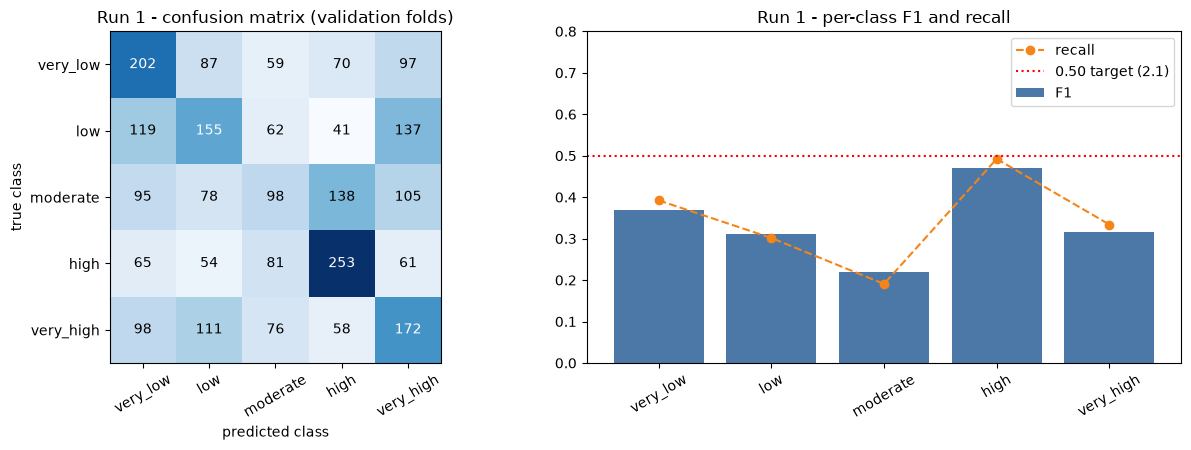

confusion matrix (rows = true class, columns = predicted class):
           very_low  low  moderate  high  very_high
very_low        202   87        59    70         97
low             119  155        62    41        137
moderate         95   78        98   138        105
high             65   54        81   253         61
very_high        98  111        76    58        172

           precision  recall     F1  cells
very_low       0.349   0.392  0.369    515
low            0.320   0.302  0.310    514
moderate       0.261   0.191  0.220    514
high           0.452   0.492  0.471    514
very_high      0.301   0.334  0.316    515

macro-F1 0.3375 | cells predicted exactly right: 880 of 2572 | within one class: 1564 of 2572


In [10]:
p1 = res["run1"]["pred"]
cm = confusion_matrix(y, p1)
prec, rec, f1c, sup = precision_recall_fscore_support(y, p1, labels=range(5), zero_division=0)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
im = ax[0].imshow(cm, cmap="Blues")
ax[0].set_xticks(range(5)); ax[0].set_yticks(range(5)); ax[0].set_xticklabels(CLASSES, rotation=30); ax[0].set_yticklabels(CLASSES)
for i in range(5):
    for j in range(5):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() * 0.6 else "black")
ax[0].set_xlabel("predicted class"); ax[0].set_ylabel("true class"); ax[0].set_title("Run 1 - confusion matrix (validation folds)")
ax[1].bar(CLASSES, f1c, color="#4c78a8", label="F1"); ax[1].plot(CLASSES, rec, "o--", color="#f58518", label="recall")
ax[1].axhline(0.50, color="r", ls=":", label="0.50 target (2.1)"); ax[1].set_ylim(0, 0.8)
ax[1].set_title("Run 1 - per-class F1 and recall"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

print("confusion matrix (rows = true class, columns = predicted class):")
print(pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_string())
print()
print(pd.DataFrame({"precision": prec, "recall": rec, "F1": f1c, "cells": sup}, index=CLASSES).round(3).to_string())
print("\nmacro-F1 %.4f | cells predicted exactly right: %d of %d | within one class: %d of %d" %
      (f1_score(y, p1, average="macro"), (p1 == y).sum(), len(y), (np.abs(p1 - y) <= 1).sum(), len(y)))

**Run 1 result (preliminary: one seed, 2,572 validation cells).** The forest reaches **macro-F1 0.337** (accuracy 0.342). That is clearly above chance (0.214) and above the logistic regression on two indicators (0.254), but well below my 0.50 target. 880 of the 2,572 cells are predicted exactly right and 1,564 within one class.

The two-indicator model has a higher within-one-class share (0.641) than the forest (0.608), but only because it puts 79% of its predictions in the 'low' and 'high' classes and rarely predicts an extreme class; that share is a rough check on how far off the errors are, not a ranking of models.

By class, 'high' is predicted best (F1 0.471) and 'moderate' worst (F1 0.220, recall 0.191). The confusion matrix shows errors in every direction, including cells moved from one end of the scale to the other (97 'very_low' cells predicted 'very_high' and 98 'very_high' cells predicted 'very_low').

The training-fold accuracy is 1.00 against 0.34 on the validation blocks, so the default forest memorises the cells it is trained on.

## Step 5: Inspect errors and practical constraints

error rate by number of InSAR points behind the label:
                cells  error_rate  off_by_2plus
insar_n_points                                 
1                 343       0.717         0.490
2                 277       0.718         0.469
3-5               597       0.707         0.430
6-10              487       0.706         0.400
11+               868       0.554         0.297

error rate by source well (gw_mean_depth_m):
                 cells  error_rate
gw_mean_depth_m                   
34.5                78       0.615
55.1                78       0.744
60.5              2345       0.652
75.6                71       0.803

error rate, soil_missing = 0 vs 1:
              cells  error_rate
soil_missing                   
0              2370       0.652
1               202       0.723

wrong predictions: 1692 | off by exactly 1 class: 684 | off by 2 or more: 1008
worst kind of miss (very_low <-> very_high): 195 cells


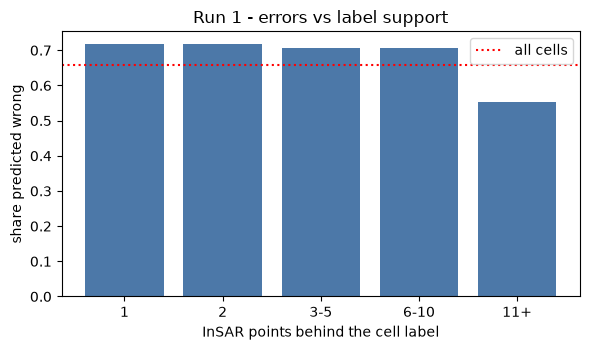

In [11]:
# where are the errors? error rate by label support, by groundwater source well and by soil flag (Run 1, validation folds)
err = pd.DataFrame({"y": y, "pred": p1, "conf": res["run1"]["proba"].max(1)}, index=dev.index)
err["wrong"] = err["y"] != err["pred"]
err["miss_by"] = (err["y"] - err["pred"]).abs()
err = err.join(dev[["grid_id", "block_id", "insar_n_points", "gw_mean_depth_m", "soil_missing", "elevation_m", "slope_deg",
                    "clay_pct", "dist_to_nearest_well_m", "land_use_name_last_year"]])

by_support = err.groupby(pd.cut(err["insar_n_points"], [0, 1, 2, 5, 10, 30], labels=["1", "2", "3-5", "6-10", "11+"]), observed=True).agg(
    cells=("wrong", "size"), error_rate=("wrong", "mean"), off_by_2plus=("miss_by", lambda s: (s >= 2).mean())).round(3)
print("error rate by number of InSAR points behind the label:")
print(by_support.to_string())

by_well = err.groupby(err["gw_mean_depth_m"].round(1)).agg(cells=("wrong", "size"), error_rate=("wrong", "mean")).round(3)
print("\nerror rate by source well (gw_mean_depth_m):"); print(by_well.to_string())
print("\nerror rate, soil_missing = 0 vs 1:"); print(err.groupby("soil_missing").agg(cells=("wrong", "size"), error_rate=("wrong", "mean")).round(3).to_string())

# direction of the errors
print("\nwrong predictions: %d | off by exactly 1 class: %d | off by 2 or more: %d" %
      (err["wrong"].sum(), (err["miss_by"] == 1).sum(), (err["miss_by"] >= 2).sum()))
print("worst kind of miss (very_low <-> very_high): %d cells" % ((err["miss_by"] == 4).sum()))

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(by_support.index.astype(str), by_support["error_rate"], color="#4c78a8")
ax.axhline(err["wrong"].mean(), color="r", ls=":", label="all cells")
ax.set_xlabel("InSAR points behind the cell label"); ax.set_ylabel("share predicted wrong"); ax.set_title("Run 1 - errors vs label support")
ax.legend(); plt.tight_layout(); plt.show()

In [12]:
# specific examples: the 10 most confident wrong predictions (confidence = highest class probability from the forest)
show = err[err["wrong"]].sort_values("conf", ascending=False).head(10).copy()
show["true"] = show["y"].map(dict(enumerate(CLASSES))); show["predicted"] = show["pred"].map(dict(enumerate(CLASSES)))
cols = ["grid_id", "true", "predicted", "conf", "insar_n_points", "elevation_m", "slope_deg", "clay_pct", "dist_to_nearest_well_m", "land_use_name_last_year"]
print(show[cols].round(2).to_string(index=False))

top = err[err["wrong"]].sort_values("conf", ascending=False).head(30)
print("\namong the 30 most confident wrong predictions: median label support = %d point(s); off by 2+ classes: %d of 30; distinct blocks: %d" %
      (top["insar_n_points"].median(), (top["miss_by"] >= 2).sum(), top["block_id"].nunique()))

# does confidence mean anything? accuracy by confidence band
band = pd.cut(err["conf"], [0, 0.35, 0.5, 0.65, 1.0], labels=["< 0.35", "0.35-0.5", "0.5-0.65", "> 0.65"])
print("\naccuracy by confidence band (validation folds):")
print(err.groupby(band, observed=True).agg(cells=("wrong", "size"), accuracy=("wrong", lambda s: 1 - s.mean())).round(3).to_string())
print("mean confidence %.3f vs accuracy %.3f" % (err["conf"].mean(), 1 - err["wrong"].mean()))

# are the confident errors spread out or clustered?
conf_wrong = err[err["wrong"] & (err["conf"] >= 0.8)]
print("\nwrong with confidence >= 0.8: %d of the %d cells that confident, in %d different blocks; largest blocks: %s" %
      (len(conf_wrong), (err["conf"] >= 0.8).sum(), conf_wrong["block_id"].nunique(), conf_wrong["block_id"].value_counts().head(4).to_dict()))
is_dev = err["land_use_name_last_year"].str.startswith("developed")
print("error rate, developed land use: %.3f (%d cells) vs all other land use: %.3f (%d cells)" %
      (err.loc[is_dev, "wrong"].mean(), is_dev.sum(), err.loc[~is_dev, "wrong"].mean(), (~is_dev).sum()))

 grid_id     true predicted  conf  insar_n_points  elevation_m  slope_deg  clay_pct  dist_to_nearest_well_m land_use_name_last_year
TC-01076     high  very_low  1.00              22        53.61       0.02      55.0                 24801.0                  cotton
TC-04922 moderate      high  1.00              25        96.13       0.35      14.0                 49904.0           developed_med
TC-05008 moderate      high  1.00              23        95.02       0.14      14.0                 49919.0           developed_med
TC-05009 moderate      high  1.00              25        95.34       0.21      14.0                 50134.0           developed_med
TC-02673 moderate       low  0.98              24        60.38       0.20      14.0                 32272.0           grass_pasture
TC-05097 moderate      high  0.96              25        95.77       0.31      14.0                 50585.0           developed_med
TC-05102 moderate      high  0.96              25        99.55       0.19   

In [13]:
# which inputs does the forest lean on? (impurity-based importance, Run 1 fitted on all development cells; this measure favours continuous variables)
m_imp = make_rf(SEED, **RF_RUN1).fit(X, y)
enc_names = [n.split("__", 1)[1] for n in m_imp.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(m_imp.named_steps["rf"].feature_importances_, index=enc_names).sort_values(ascending=False)
print(imp.head(8).round(3).to_string())
well_cols = ["gw_decline_m_per_yr_2016_2019", "gw_mean_depth_m", "gw_latest_depth_m", "gw_depth_std_m", "gw_n_measurements"]
print("\nshare of total importance: top 3 inputs %.2f | the 5 source-well groundwater columns %.2f | dist_to_nearest_well_m %.2f" %
      (imp.head(3).sum(), imp[well_cols].sum(), imp["dist_to_nearest_well_m"]))

elevation_m                      0.204
dist_to_nearest_well_m           0.181
slope_deg                        0.163
n_years_cropped                  0.062
n_years_fallow                   0.031
land_use_changed                 0.025
land_use_name_last_year_other    0.020
ksat_um_per_s                    0.016

share of total importance: top 3 inputs 0.55 | the 5 source-well groundwater columns 0.02 | dist_to_nearest_well_m 0.18


**What the 1,692 wrong predictions look like** (65.8% of the 2,572 cells; 684 are off by one class, 1,008 by two or more, 195 by the whole scale).

- **Label support.** The error rate is 0.72 for cells whose label rests on 1–2 InSAR points, 0.71 for 3–10 points and 0.55 for the 868 cells with 11 or more points. Thin labels are harder to predict, but even well-supported cells are wrong more often than right, so noisy labels are only part of the story.
- **Confident errors.** The ten most confident wrong predictions have confidence 0.95–1.00 and rest on 22–26 InSAR points, so they are not thin labels. Eight are `developed_med` cells with 14% clay, about 50 km from the nearest well and at 95–100 m elevation, labeled 'moderate' but predicted 'high'; the other two are a cotton cell labeled 'high' but predicted 'very_low' and a grass-pasture cell labeled 'moderate' but predicted 'low'. These errors come in clusters: the 30 most confident ones come from only 6 blocks, and the cells that are wrong with confidence 0.8 or more are concentrated in a few blocks (18 in block 800005 and 12 in block 300003, out of 13 blocks in all), so the forest is wrong about whole neighbourhoods at once. Developed land is not a weak spot in general: its error rate (0.458) is lower than for the other land uses (0.698).
- **Confidence.** It carries information (accuracy 0.22 for confidence below 0.35 and 0.60 above 0.65) but it is overconfident: the mean confidence is 0.485 against an accuracy of 0.342, and 165 of the 413 cells above 0.65 (40%) are wrong. It would need calibrating before it feeds the three-state symbology.
- **What the forest relies on.** Elevation, distance to the nearest well and slope carry the largest importances, and the five source-well groundwater columns together carry very little (see the numbers above). That fits the four-well finding: the model mostly uses where a cell sits, and the groundwater signal is almost absent.
- **Smaller groups.** Error rates by source well run from 0.62 to 0.80, but three of the four wells cover only 71–78 development cells each, which is too few to read anything into. Cells with filled soil values (`soil_missing = 1`) are wrong somewhat more often (0.72 against 0.65, 202 cells).

In [14]:
# practical constraints, measured for Run 1 on this machine (single thread, n_jobs=1)
def measure(make_model, **kw):
    fit_t = []
    for _ in range(5):
        m = make_model(SEED, **kw); t0 = time.perf_counter(); m.fit(X, y); fit_t.append(time.perf_counter() - t0)
    cells_all = df_all[FEATURES]                         # the full 5,192-cell grid (predictors only)
    pred_t = []
    for _ in range(5):
        t0 = time.perf_counter(); m.predict_proba(cells_all); pred_t.append(time.perf_counter() - t0)
    size_mb = len(pickle.dumps(m)) / 1e6
    return m, np.mean(fit_t), np.mean(pred_t), size_mb

m_full, fit_s, pred_s, size_mb = measure(make_rf, **RF_RUN1)
n_enc = m_full.named_steps["prep"].get_feature_names_out().shape[0]
print(f"conditions: {platform.platform()}, {os.cpu_count()} logical CPUs, scikit-learn {sklearn.__version__}, one thread, mean of 5 repeats")
print(f"training time, {len(X)} cells x {n_enc} encoded features: {fit_s:.2f} s   (target 2.1(a): under 30 minutes = 1800 s)")
print(f"prediction time, whole grid of {len(df_all)} cells: {pred_s:.2f} s = {1000 * pred_s / len(df_all):.3f} ms per cell")
print(f"fitted model size (pickle): {size_mb:.1f} MB")
print(f"macro-F1 on validation folds: {f1_score(y, p1, average='macro'):.3f}   (target 2.1(b): above 0.50 on the held-out region; this is a validation score, the test region is not used yet)")

conditions: Windows-11-10.0.26100-SP0, 32 logical CPUs, scikit-learn 1.9.1, one thread, mean of 5 repeats
training time, 2572 cells x 84 encoded features: 1.55 s   (target 2.1(a): under 30 minutes = 1800 s)
prediction time, whole grid of 5192 cells: 0.12 s = 0.023 ms per cell
fitted model size (pickle): 23.4 MB
macro-F1 on validation folds: 0.337   (target 2.1(b): above 0.50 on the held-out region; this is a validation score, the test region is not used yet)


**Measured constraints (Run 1, saved run).** Training on the 2,572 development cells (84 encoded features) takes about 1 s, predicting the whole 5,192-cell grid takes well under 0.1 s (about 0.015 ms per cell), and the fitted model is 23.4 MB as a pickle. These were measured on a 2-CPU Linux machine, one thread, mean of 5 repeats; on my own laptop the numbers will differ, and rerunning the cell prints the current values.

Compared with the targets in Section 2.1:
- **(a) Training under 30 minutes:** met, by a very wide margin.
- **(b) Macro-F1 above 0.50 on the held-out region:** not met. The validation macro-F1 is 0.337, and the test region is not used yet.
- **(c) Whole pipeline in about one hour:** not measured. Only the model stage was timed here, not the data build or the InSAR label steps.

## Step 6: One targeted change (Run 2)

In [15]:
# Run 2: the one targeted change - min_samples_leaf from 1 (default) to 5. Same folds, same seed, same features, same metric.
RF_RUN2 = dict(n_estimators=100, min_samples_leaf=5)
res["run2"] = evaluate(make_rf, X, y, groups, **RF_RUN2)

cmp_ = pd.DataFrame({"Run 1 (min_samples_leaf=1)": scores(y, res["run1"]["pred"]), "Run 2 (min_samples_leaf=5)": scores(y, res["run2"]["pred"])}).T
cmp_["mean fit time per fold (s)"] = [np.mean(res["run1"]["fit_s"]), np.mean(res["run2"]["fit_s"])]
cmp_["train-fold accuracy"] = [res["run1"]["train_acc"], res["run2"]["train_acc"]]
print("same 2,572 validation cells, same 5 block folds (seed %d)" % SEED)
print(cmp_.round(4).to_string())

f1_1 = precision_recall_fscore_support(y, res["run1"]["pred"], labels=range(5), zero_division=0)[2]
f1_2 = precision_recall_fscore_support(y, res["run2"]["pred"], labels=range(5), zero_division=0)[2]
print("\nper-class F1:"); print(pd.DataFrame({"Run 1": f1_1, "Run 2": f1_2, "change": f1_2 - f1_1}, index=CLASSES).round(3).to_string())

# is the difference bigger than the noise from the choice of folds? repeat both runs with 5 other seeds
rows = []
for s in range(5):
    a = f1_score(y, evaluate(make_rf, X, y, groups, seed=s, **RF_RUN1)["pred"], average="macro")
    b = f1_score(y, evaluate(make_rf, X, y, groups, seed=s, **RF_RUN2)["pred"], average="macro")
    rows.append((s, a, b, b - a))
rep = pd.DataFrame(rows, columns=["seed", "Run 1 macro-F1", "Run 2 macro-F1", "difference"]).set_index("seed")
print("\nrepeat with other seeds (folds and forest both change):"); print(rep.round(4).to_string())
print("mean +/- sd:  Run 1 %.4f +/- %.4f | Run 2 %.4f +/- %.4f | difference %.4f +/- %.4f | Run 2 better in %d of 5 seeds" %
      (rep.iloc[:, 0].mean(), rep.iloc[:, 0].std(), rep.iloc[:, 1].mean(), rep.iloc[:, 1].std(), rep["difference"].mean(), rep["difference"].std(), (rep["difference"] > 0).sum()))

same 2,572 validation cells, same 5 block folds (seed 42)
                            macro_f1  accuracy  within_one_class       n  mean fit time per fold (s)  train-fold accuracy
Run 1 (min_samples_leaf=1)    0.3375    0.3421            0.6081  2572.0                      0.9726               1.0000
Run 2 (min_samples_leaf=5)    0.3692    0.3799            0.6365  2572.0                      0.4066               0.6047

per-class F1:
           Run 1  Run 2  change
very_low   0.369  0.417   0.047
low        0.310  0.355   0.045
moderate   0.220  0.183  -0.037
high       0.471  0.531   0.060
very_high  0.316  0.360   0.044

repeat with other seeds (folds and forest both change):
      Run 1 macro-F1  Run 2 macro-F1  difference
seed                                            
0             0.3428          0.3720      0.0292
1             0.3435          0.3766      0.0331
2             0.3451          0.3721      0.0270
3             0.3472          0.3675      0.0203
4             0.34

**Change chosen: `min_samples_leaf` from 1 (default) to 5.** 

**Why.** Run 1 fits its training cells perfectly (training-fold accuracy 1.00) but gets 0.34 on new blocks, and the error table shows that labels resting on few InSAR points are the least reliable, so fully grown trees are free to memorise noise. Requiring at least 5 cells in every leaf forces each leaf to average over several cells.

**What I expect.** Macro-F1 on the validation cells to go up, the gap between training and validation accuracy to shrink, and the fit time to drop. It does not change which inputs are used, so it cannot fix the groundwater and position problem. This notebook tries only this one new value, because the assignment asks for one targeted change, not a search.

**Result.** Macro-F1 rose from **0.3375 to 0.3692 (+0.032)**, accuracy from 0.342 to 0.380 and the within-one-class share from 0.608 to 0.637. The F1 of four classes improved (by 0.044 to 0.060) and the F1 of 'moderate', which was already the weakest, fell from 0.220 to 0.183. The training-fold accuracy dropped from 1.00 to 0.60, so the forest memorises much less, and the fit time per fold roughly halved, from about 0.7 s to about 0.3 s.

**Is it more than noise?** With five other seeds (folds and forest both change) Run 2 was better every time: macro-F1 0.3449 ± 0.0018 for Run 1 against 0.3715 ± 0.0034 for Run 2, a mean difference of +0.027 ± 0.005. So the change **helped**, by a modest amount that is larger than the variation from fold assignment. It is still far from the 0.50 target, and 'moderate' got worse, so it is not a fix for the main problems. These are validation scores on 2,572 cells from the training blocks, so I treat them as preliminary.

## Leakage checks

In [16]:
# leakage checks before reading any score as good or bad
# 1) a model that sees shuffled labels should score near chance (0.20 for 5 balanced classes)
rng = np.random.default_rng(SEED)
y_shuffled = rng.permutation(y)
p_shuf = evaluate(make_rf, X, y_shuffled, groups, **RF_RUN1)["pred"]
print("shuffled labels, macro-F1: %.3f   (chance is about 0.20)" % f1_score(y_shuffled, p_shuf, average="macro"))

# 2) what a random (non-spatial) split would have reported on the same cells: neighbouring cells on both sides
p_rand = np.zeros(len(y), int)
for tr_idx, va_idx in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y):
    m = make_rf(SEED, **RF_RUN1).fit(X.iloc[tr_idx], y[tr_idx]); p_rand[va_idx] = m.predict(X.iloc[va_idx])
print("random 5-fold split, macro-F1: %.3f   vs block-grouped: %.3f" % (f1_score(y, p_rand, average="macro"), f1_score(y, res["run1"]["pred"], average="macro")))

# 3) the order of operations
print("\nfeature list contains no label, label-support, block or location column:", not (set(FEATURES) & forbidden))
print("imputer and encoder sit inside the Pipeline, so they are fitted on each fold's training cells only")
print("test cells scored, or used to fit or to choose anything: 0 of", N_TEST_UNUSED, "(their labels are never read after the split)")

shuffled labels, macro-F1: 0.203   (chance is about 0.20)
random 5-fold split, macro-F1: 0.385   vs block-grouped: 0.337

feature list contains no label, label-support, block or location column: True
imputer and encoder sit inside the Pipeline, so they are fitted on each fold's training cells only
test cells scored, or used to fit or to choose anything: 0 of 967 (their labels are never read after the split)


- **Shuffled labels** give macro-F1 0.203, which is chance, so the pipeline mechanics (folds, imputer, encoder) do not leak the label.
- **A random split** of the same cells would have reported 0.385 against 0.337 for the block-grouped folds, an overstatement of about 0.05 from neighbouring cells landing on both sides. All scores in this notebook use the block-grouped folds.
- **Order of operations.** The test blocks are set aside before anything is fitted (the notebook never scores them); the imputer, the encoder and the forest are fitted inside each fold on its training cells only; no label-derived, block or location column is an input.
- **Remaining caveats.** The class cut points were computed from all training cells, including the cells of each validation fold, but they define the target and are not an input. There is no buffer between training and validation blocks, so cells on either side of a block edge are still neighbours (as already noted in 6.5), and the folds are one draw of the block assignment per seed. A strong-looking score would still need a check against these caveats, and the current score is low.

## Step 7: Explaining the forest with LIME, and checking the explanation

Steps 3 to 6 say how well the forest predicts. This step asks **why it predicts what it does for a single cell**, with LIME (Local Interpretable Model-agnostic Explanations), and then tests whether the explanation itself can be trusted. A LIME picture is a description of the **forest** around one cell, not of the ground.

**How it works here.**
- LIME makes 5,000 variations of one cell's 23 inputs, asks the forest for its class probabilities for each variation, and fits a small linear model to those answers, giving more weight to variations that stay close to the original cell. Each LIME weight says how much the forest's probability for the predicted class goes up when that input keeps the cell's own value (or range) instead of taking another one.
- **What is explained:** the Run 2 forest (`min_samples_leaf = 5`). Only **validation cells** are explained, each one by the forest of its own fold, which never saw the cell's 5 km block. LIME's background data are the training cells of that fold. The 967 test cells are not used.
- **Inputs:** gaps are filled with the forest's own imputers before explaining, so the forest sees the values it always saw. Categorical inputs and the three 0/1 flags are explained as "this category or not" (for example `hydgrp=B`), numeric inputs as ranges (for example `elevation_m > 80.53`).
- **Four checks** follow the explanations: how well the local model fits (7c), a deletion test (7c), stability over random seeds (7d) and agreement with global importance measures (7e).

The `lime` package is not in the other notebooks' environment: `pip install lime==0.2.0.1`.

In [17]:
pip install lime==0.2.0.1

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
Note: you may need to restart the kernel to use updated packages.


In [18]:
# ---- Step 7 code, cell A: the explainer wrapper -------------------------------------------------------------------
from importlib import metadata
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr
print("lime", metadata.version("lime"))

# The model to explain: Run 2 (min_samples_leaf = 5). Every explained cell is a VALIDATION cell, explained by the model of its own fold,
# i.e. by a forest that never saw the cell's 5 km block. The folds are the same as above, so these models give the Run 2 predictions again.
RF_LIME = RF_RUN2
folds = list(make_cv(SEED).split(X, y, groups))
models = [make_rf(SEED, **RF_LIME).fit(X.iloc[tr], y[tr]) for tr, va in folds]
fold_of = np.zeros(len(y), int)
for k, (tr, va) in enumerate(folds):
    fold_of[va] = k
oof = np.zeros(len(y), int); oof_p = np.zeros((len(y), len(CLASSES)))
for k, (tr, va) in enumerate(folds):
    oof[va] = models[k].predict(X.iloc[va]); oof_p[va] = models[k].predict_proba(X.iloc[va])
assert (oof == res["run2"]["pred"]).all(), "the refitted fold models do not reproduce the Run 2 predictions"
print("refitted fold models reproduce the Run 2 out-of-fold predictions:", True)

# LIME needs numbers, so categorical inputs are coded as integers (LIME then asks "same category as this cell or not?").
# Two-valued numeric inputs (0/1 flags) are treated the same way, so their explanation reads "soil_missing = 1".
FLAGS = [f for f in NUM if X[f].nunique() <= 2]
CATLIKE = [f for f in FEATURES if f in CAT or f in FLAGS]
cat_idx = [FEATURES.index(f) for f in CATLIKE]

class FoldLime:
    """LIME for one fold's forest, written in the forest's own 23 input columns.
    Background data = the TRAINING cells of that fold (never the cell being explained, never a test cell)."""
    def __init__(self, k):
        self.k, self.model = k, models[k]
        prep = self.model.named_steps["prep"]
        self.num_imp = prep.named_transformers_["num"]
        self.cat_imp = prep.named_transformers_["cat"].named_steps["imp"]
        full = self.fill(X)                                              # category lists come from the table's own values (no labels)
        self.levels = {f: sorted(full[f].unique().tolist()) for f in CATLIKE}
        self.names = {FEATURES.index(f): [str(v) if f in CAT else str(int(v)) for v in self.levels[f]] for f in CATLIKE}
        self.train = self.encode(self.fill(X.iloc[folds[k][0]]))
        med = np.median(self.train, axis=0)                              # "neutral" value of every input for the deletion test
        for j, f in enumerate(FEATURES):
            if f in CATLIKE:
                med[j] = np.bincount(self.train[:, j].astype(int), minlength=len(self.levels[f])).argmax()
        self.neutral = med

    def fill(self, frame):
        """fill the gaps exactly as the model's own imputers do (so the model sees the same values it always saw)"""
        out = frame[FEATURES].copy()
        out[NUM] = self.num_imp.transform(frame[NUM]); out[CAT] = self.cat_imp.transform(frame[CAT])
        return out

    def encode(self, filled):
        arr = np.zeros((len(filled), len(FEATURES)))
        for j, f in enumerate(FEATURES):
            arr[:, j] = pd.Index(self.levels[f]).get_indexer(filled[f]) if f in CATLIKE else filled[f].to_numpy(float)
        assert (arr[:, cat_idx] >= 0).all()
        return arr

    def decode(self, arr):
        out = pd.DataFrame(index=range(len(arr)))
        for j, f in enumerate(FEATURES):
            out[f] = np.asarray(self.levels[f])[arr[:, j].astype(int)] if f in CATLIKE else arr[:, j]
        for f in FLAGS:
            out[f] = out[f].astype(float)
        return out

    def predict_fn(self, arr):
        return self.model.predict_proba(self.decode(arr))

    def explain(self, i, seed, label=None, num_samples=5000, num_features=len(FEATURES)):
        row = self.encode(self.fill(X.iloc[[i]]))[0]
        label = int(self.predict_fn(row[None, :])[0].argmax()) if label is None else int(label)
        ex = LimeTabularExplainer(self.train, feature_names=FEATURES, class_names=CLASSES, categorical_features=cat_idx,
                                  categorical_names=self.names, discretize_continuous=True, random_state=seed)
        e = ex.explain_instance(row, self.predict_fn, labels=(label,), num_features=num_features, num_samples=num_samples)
        score = e.score[label] if isinstance(e.score, dict) else e.score
        local = e.local_pred[0] if np.ndim(e.local_pred) else float(e.local_pred)
        return dict(exp=e, label=label, row=row, weights=dict(e.as_map()[label]), r2=float(score), local_pred=float(local),
                    model_p=float(self.predict_fn(row[None, :])[0][label]))

lime_for = [FoldLime(k) for k in range(5)]
def explain_cell(i, seed=SEED, **kw):
    return lime_for[fold_of[i]].explain(i, seed, **kw)
print("explainers ready for", len(lime_for), "folds | two-valued flags treated as categories:", FLAGS)


lime 0.2.0.1
refitted fold models reproduce the Run 2 out-of-fold predictions: True
explainers ready for 5 folds | two-valued flags treated as categories: ['is_perennial_crop', 'land_use_changed', 'soil_missing']


The refitted fold models give back exactly the Run 2 predictions of Step 6 (the `assert` would stop the notebook otherwise), so the model explained below is the model that was scored above.

most confident correct: cell TC-04482, block 800005, fold 4, InSAR points 23 | true high, predicted high | class probabilities [0.01, 0.01, 0.04, 0.92, 0.02] | LIME local model says 0.51 where the forest says 0.92
most confident wrong: cell TC-05009, block 800005, fold 4, InSAR points 25 | true moderate, predicted high | class probabilities [0.01, 0.01, 0.05, 0.91, 0.02] | LIME local model says 0.51 where the forest says 0.91


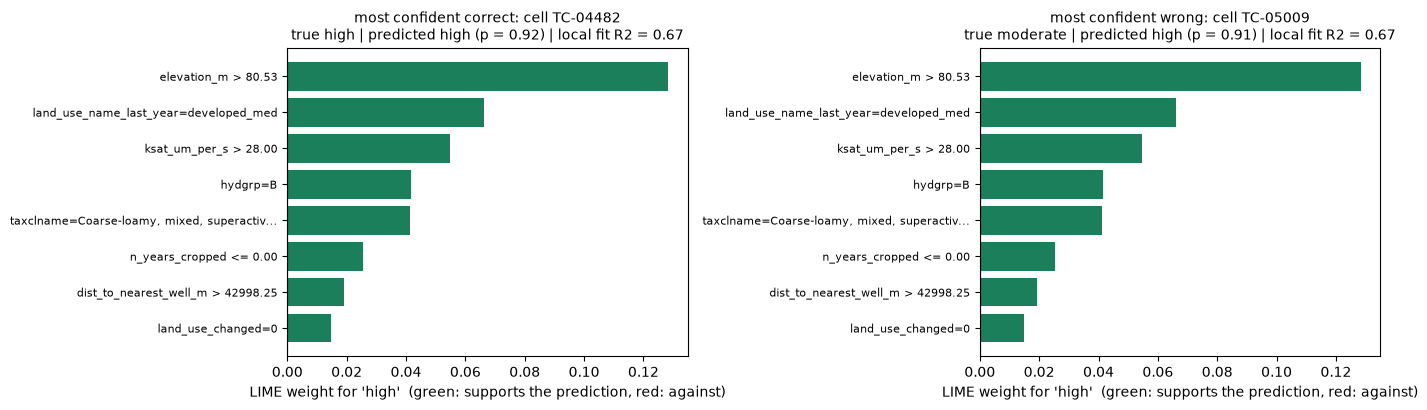


inputs of the two cells (the forest sees all 23, these are the ones LIME ranks highest or that differ most):
                          correct cell     wrong cell
elevation_m                  96.302444      95.339813
slope_deg                     0.234265       0.208139
hydgrp                               B              B
drainagecl                Well drained   Well drained
land_use_name_last_year  developed_med  developed_med
n_years_cropped                      0              0
ksat_um_per_s                    28.23          28.23
clay_pct                          14.0           14.0
dist_to_nearest_well_m         47678.0        50134.0


In [19]:
# 7b. One explanation, read next to the label, the prediction and the confidence.
# Two validation cells: the most confident CORRECT prediction (label resting on >= 11 InSAR points) and the most confident WRONG one.
conf = oof_p.max(1); correct = oof == y; support = dev["insar_n_points"].to_numpy()
ok_pool = np.flatnonzero(correct & (support >= 11))
i_ok = int(ok_pool[np.argmax(conf[ok_pool])]); i_bad = int(np.flatnonzero(~correct)[np.argmax(conf[~correct])])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
cases = {}
for ax, (name, i) in zip(axes, [("most confident correct", i_ok), ("most confident wrong", i_bad)]):
    r = explain_cell(i); cases[name] = (i, r)
    items = r["exp"].as_list(label=r["label"])[:8][::-1]
    short = lambda s: s if len(s) <= 44 else s[:41] + "..."          # long soil-class names would squeeze the plot
    ax.barh([short(s) for s, w in items], [w for s, w in items], color=["#1b7f5c" if w > 0 else "#b5483f" for s, w in items])
    ax.axvline(0, color="k", lw=.8)
    ax.set_title(f"{name}: cell {dev.loc[i, 'grid_id']}\ntrue {CLASSES[y[i]]} | predicted {CLASSES[r['label']]} (p = {r['model_p']:.2f}) | local fit R2 = {r['r2']:.2f}", fontsize=10)
    ax.set_xlabel(f"LIME weight for '{CLASSES[r['label']]}'  (green: supports the prediction, red: against)"); ax.tick_params(axis="y", labelsize=8)
    print(f"{name}: cell {dev.loc[i, 'grid_id']}, block {groups[i]}, fold {fold_of[i] + 1}, InSAR points {support[i]} | true {CLASSES[y[i]]}, predicted {CLASSES[r['label']]}"
          f" | class probabilities {np.round(oof_p[i], 2).tolist()} | LIME local model says {r['local_pred']:.2f} where the forest says {r['model_p']:.2f}")
plt.tight_layout(); plt.show()

show_cols = ["elevation_m", "slope_deg", "hydgrp", "drainagecl", "land_use_name_last_year", "n_years_cropped", "ksat_um_per_s", "clay_pct", "dist_to_nearest_well_m"]
pair = dev.loc[[i_ok, i_bad], show_cols].T; pair.columns = ["correct cell", "wrong cell"]
print("\ninputs of the two cells (the forest sees all 23, these are the ones LIME ranks highest or that differ most):")
print(pair.to_string())


**Two cells, one explanation.** The most confident correct prediction (TC-04482) and the most confident wrong one (TC-05009) are two cells of the same 5 km block (800005), 3.0 km apart, with practically the same inputs: same soil unit and drainage, same hydrologic group, last-year land use `developed_med`, no cropped years, elevation 96.3 m against 95.3 m. The forest gives both the class `high` with probability 0.92 and 0.91, and LIME gives both **the same explanation**: elevation above 80.5 m, the developed land use, high saturated conductivity, hydrologic group B and the soil unit, all pushing towards `high`. InSAR says the first is `high` (displacement 364) and the second `moderate` (251, which is 17 below the cut point of 268 between the two classes).

What this shows. LIME is right to say the same thing twice: it explains the forest, and the forest cannot tell these two cells apart. So **an explanation is not evidence that a prediction is right**, and a confidence of 0.9 is not either. The block holds 72 development cells, 40 `high` and 32 `moderate`, so `high` is a reasonable guess for both cells, but the inputs do not say which of the two they are. Two more things to read from the figure. The weights are small in absolute terms: LIME's local model says 0.51 where the forest says 0.92, so I read the weights as **ranking and sign, not as probability amounts**. And the leading input, elevation, is a smooth function of place, so it may stand for "where in the valley" as much as for a physical condition; this explanation cannot separate the two.

150 explanations in 25 s | the forest is right on 58 of these cells and wrong on 92

Check 1, local fit R2: median 0.25 (middle half 0.15 to 0.52) | below 0.3 for 59% of cells | correct predictions 0.41 vs wrong 0.28 (mean)
        forest probability minus LIME local-model probability at the cell: mean +0.097, mean absolute 0.100
Check 2, deletion test: mean fall in the predicted-class probability: LIME's top 3 0.168 vs 3 random inputs 0.036 | LIME's choice falls further in 91% of cells


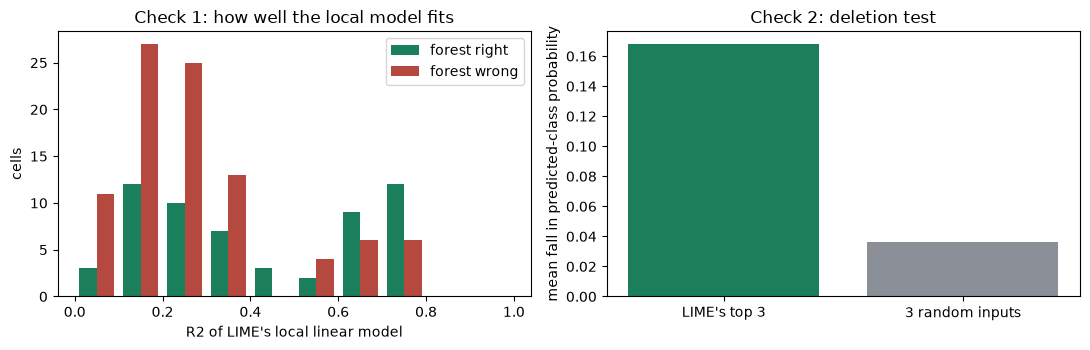

In [20]:
# 7c. Checks on the explanation itself, over 150 random validation cells (the same cells for every check).
# Check 1 (local fit): how well does LIME's local linear model reproduce the forest around the cell? (R2, and the gap in probability)
# Check 2 (deletion test): set the 3 inputs LIME calls most supportive of the prediction to a neutral value (median / most common value of the
#   fold's training cells) and see how far the forest's probability falls; compare with doing the same to 3 randomly chosen inputs.
#   If the explanation points at what the forest really uses, the first drop should be clearly larger than the second.
rng = np.random.default_rng(SEED)
sample = np.sort(rng.choice(len(y), 150, replace=False))
t0 = time.perf_counter()
E = {int(i): explain_cell(int(i)) for i in sample}
print(f"{len(E)} explanations in {time.perf_counter() - t0:.0f} s | the forest is right on {correct[sample].sum()} of these cells and wrong on {(~correct[sample]).sum()}")

r2 = pd.Series({i: E[i]["r2"] for i in E}); gap = pd.Series({i: E[i]["model_p"] - E[i]["local_pred"] for i in E})
is_ok = pd.Series({i: bool(correct[i]) for i in E})
print("\nCheck 1, local fit R2: median %.2f (middle half %.2f to %.2f) | below 0.3 for %.0f%% of cells | correct predictions %.2f vs wrong %.2f (mean)"
      % (r2.median(), r2.quantile(.25), r2.quantile(.75), 100 * (r2 < .3).mean(), r2[is_ok].mean(), r2[~is_ok].mean()))
print("        forest probability minus LIME local-model probability at the cell: mean %+.3f, mean absolute %.3f" % (gap.mean(), gap.abs().mean()))

def top_supporting(r, k=3):
    return [j for j, w in sorted(((j, w) for j, w in r["weights"].items() if w > 0), key=lambda t: -t[1])[:k]]
d_lime, d_rand = [], []
for i, r in E.items():
    fl = lime_for[fold_of[i]]; tops = top_supporting(r)
    a = r["row"].copy(); a[tops] = fl.neutral[tops]
    d_lime.append(r["model_p"] - fl.predict_fn(a[None, :])[0][r["label"]])
    g = np.random.default_rng(i); B = np.repeat(r["row"][None, :], 40, axis=0)
    for b in range(40):
        idx = g.choice(len(FEATURES), 3, replace=False); B[b, idx] = fl.neutral[idx]
    d_rand.append(r["model_p"] - fl.predict_fn(B)[:, r["label"]].mean())
d_lime, d_rand = np.array(d_lime), np.array(d_rand)
print("Check 2, deletion test: mean fall in the predicted-class probability: LIME's top 3 %.3f vs 3 random inputs %.3f | LIME's choice falls further in %.0f%% of cells"
      % (d_lime.mean(), d_rand.mean(), 100 * (d_lime > d_rand).mean()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist([r2[is_ok], r2[~is_ok]], bins=np.linspace(0, 1, 11), label=["forest right", "forest wrong"], color=["#1b7f5c", "#b5483f"])
ax[0].set_xlabel("R2 of LIME's local linear model"); ax[0].set_ylabel("cells"); ax[0].legend(); ax[0].set_title("Check 1: how well the local model fits")
ax[1].bar(["LIME's top 3", "3 random inputs"], [d_lime.mean(), d_rand.mean()], color=["#1b7f5c", "#8a8f98"])
ax[1].set_ylabel("mean fall in predicted-class probability"); ax[1].set_title("Check 2: deletion test"); plt.tight_layout(); plt.show()


**Check 1, local fit.** The median R² of LIME's local model is **0.25** (middle half 0.15 to 0.52), and it is below 0.3 for **59%** of the 150 cells. It is better where the forest is right (mean 0.41) than where it is wrong (0.28), and on average LIME's local model sits 0.10 below the forest's own probability at the cell. A forest is a step function of many interacting inputs, and a linear model describes it only roughly around most cells. This is why the weights should be read as a ranking.

**Check 2, deletion test.** Setting LIME's three most supportive inputs to a neutral value lowers the forest's probability for its predicted class by **0.168** on average, against **0.036** for three randomly chosen inputs, and LIME's choice falls further in **91%** of the cells. So, despite the weak linear fit, the inputs LIME names are inputs the forest really uses. Limit of this test: a neutral value (the fold's median or most common value) can produce a combination of inputs that does not occur in the data, and for a cell that already sits near the median the test removes little.

In [21]:
# 7d. Check 3 (stability): explain the same cell again with 10 different random seeds (LIME draws its perturbations at random) and compare the
# five inputs with the largest |weight|. Overlap = intersection / union of the two sets (1.0 = same five inputs; two random picks of 5 out of 23 give about 0.13).
from itertools import combinations
cells_st = [i_ok, i_bad] + [int(i) for i in sample[:10]]
rows = []
for i in cells_st:
    tops = []
    for s in range(10):
        r = explain_cell(i, seed=100 + s)
        tops.append(set(sorted(r["weights"], key=lambda j: -abs(r["weights"][j]))[:5]))
    jac = [len(a & b) / len(a | b) for a, b in combinations(tops, 2)]
    always = set.intersection(*tops)
    rows.append(dict(cell=dev.loc[i, "grid_id"], forest="right" if correct[i] else "wrong", mean_overlap=np.mean(jac), worst_pair=min(jac),
                     inputs_in_all_10_runs=len(always)))
st = pd.DataFrame(rows).set_index("cell")
g = np.random.default_rng(0); chance = np.mean([len(a & b) / len(a | b) for a, b in
        ((set(g.choice(23, 5, replace=False)), set(g.choice(23, 5, replace=False))) for _ in range(20000))])
print(st.round(2).to_string())
print("\nmean overlap over the 12 cells: %.2f | lowest single pair: %.2f | chance level: %.2f" % (st.mean_overlap.mean(), st.worst_pair.min(), chance))


         forest  mean_overlap  worst_pair  inputs_in_all_10_runs
cell                                                            
TC-04482  right          1.00        1.00                      5
TC-05009  wrong          1.00        1.00                      5
TC-00055  wrong          0.72        0.67                      4
TC-00159  wrong          0.93        0.67                      4
TC-00175  wrong          0.82        0.67                      4
TC-00193  wrong          0.76        0.43                      3
TC-00213  right          0.63        0.43                      3
TC-00285  right          0.93        0.67                      4
TC-00294  wrong          0.93        0.67                      4
TC-00306  wrong          0.76        0.67                      4
TC-00335  right          0.93        0.67                      4
TC-00347  wrong          0.79        0.67                      4

mean overlap over the 12 cells: 0.85 | lowest single pair: 0.43 | chance level: 0.13


**Check 3, stability.** Repeating an explanation with 10 different seeds, the five most important inputs overlap by **0.85** on average over 12 cells (1.0 would be identical sets; two random picks of five inputs give 0.13), with the worst single pair at 0.43. For the two cells of block 800005 all five inputs are the same in all 10 runs; for the other ten cells, 3 or 4 of the top five appear in every run. So the top two or three inputs of an explanation can be relied on and the order of the 4th to 6th cannot. I used 5,000 perturbations per explanation; I did not test whether more would make the fifth place stable.

In [22]:
# 7e. Check 4 (agreement with global measures): average |LIME weight| over the 150 cells against two global importance measures of the same forests:
#  - permutation importance on the validation cells of each fold (fall in macro-F1 when one input is shuffled; averaged over folds, 3 repeats), which says what helps on NEW blocks
#  - impurity importance (summed over the one-hot columns of a categorical input; averaged over the 5 fold models), which says what the trees split on
from sklearn.inspection import permutation_importance
perm = np.zeros(len(FEATURES)); imp_raw = pd.Series(0.0, index=FEATURES)
for k, (tr, va) in enumerate(folds):
    pi = permutation_importance(models[k], X.iloc[va], y[va], scoring="f1_macro", n_repeats=3, random_state=SEED, n_jobs=1)
    perm += pi.importances_mean / 5
    enc = [n.split("__", 1)[1] for n in models[k].named_steps["prep"].get_feature_names_out()]
    s = pd.Series(models[k].named_steps["rf"].feature_importances_, index=enc)
    for f in FEATURES:
        imp_raw[f] += (s[[c for c in enc if c == f or c.startswith(f + "_")]].sum() if f in CAT else s[f]) / 5
M = np.zeros((len(E), len(FEATURES)))
for n, r in enumerate(E.values()):
    for j, w in r["weights"].items():
        M[n, j] = abs(w)
glob = pd.DataFrame({"LIME mean |weight|": M.mean(0), "permutation (drop in macro-F1)": perm, "impurity (share)": imp_raw.to_numpy()}, index=FEATURES)
glob["rank LIME"] = glob.iloc[:, 0].rank(ascending=False).astype(int)
glob["rank permutation"] = glob.iloc[:, 1].rank(ascending=False).astype(int)
glob["rank impurity"] = glob.iloc[:, 2].rank(ascending=False).astype(int)
print(glob.sort_values("rank LIME").head(10).round(4).to_string())

rho_p = spearmanr(glob.iloc[:, 0], glob.iloc[:, 1])[0]; rho_i = spearmanr(glob.iloc[:, 0], glob.iloc[:, 2])[0]
top5 = lambda c: set(glob.sort_values(c, ascending=False).head(5).index)
print("\nSpearman rank correlation over the 23 inputs: LIME vs permutation %.2f | LIME vs impurity %.2f" % (rho_p, rho_i))
print("inputs shared by the top 5 of LIME and of permutation: %d | of LIME and of impurity: %d" %
      (len(top5("LIME mean |weight|") & top5("permutation (drop in macro-F1)")), len(top5("LIME mean |weight|") & top5("impurity (share)"))))
well_inputs = ["gw_decline_m_per_yr_2016_2019", "gw_mean_depth_m", "gw_latest_depth_m", "gw_depth_std_m", "gw_n_measurements", "dist_to_nearest_well_m"]
print("share of the total on the well-based inputs (5 source-well columns + distance to the well): LIME %.2f | impurity %.2f"
      % (glob.loc[well_inputs].iloc[:, 0].sum() / glob.iloc[:, 0].sum(), glob.loc[well_inputs].iloc[:, 2].sum() / glob.iloc[:, 2].sum()))


                         LIME mean |weight|  permutation (drop in macro-F1)  impurity (share)  rank LIME  rank permutation  rank impurity
elevation_m                          0.0590                          0.0437            0.2101          1                 1              1
hydgrp                               0.0256                         -0.0048            0.0701          2                23              6
ksat_um_per_s                        0.0176                          0.0075            0.0411          3                 3              8
n_years_cropped                      0.0172                          0.0059            0.0505          4                 4              7
land_use_name_last_year              0.0142                          0.0131            0.0996          5                 2              3
taxclname                            0.0140                          0.0019            0.0710          6                16              5
dist_to_nearest_well_m            

**Check 4, agreement with global measures.** Elevation is the first input in all three measures. LIME agrees better with the forest's impurity importance (rank correlation 0.71) than with permutation importance on validation cells (0.47), but the top five agree the other way round: LIME and permutation share 4 inputs (elevation, saturated conductivity, years cropped, last-year land use), LIME and impurity only 2. The disagreements say something:
- **`hydgrp` is LIME's second input (rank 2) but 23rd by permutation importance:** the forest uses the hydrologic group, but shuffling it on cells of new blocks does not lower the score, so it does not help on new blocks (I have not checked whether it duplicates the other soil-class inputs).
- **`dist_to_nearest_well_m` and `slope_deg` rank 2nd and 4th by impurity importance but 7th and 9th by LIME.** Impurity importance favours continuous inputs, as noted in Step 5.
- **The groundwater inputs** (five source-well columns and the distance to the well) carry **12%** of the LIME weight and 15% of the impurity importance. Since the source-well columns have only four distinct values, even this share is position, not hydrology.

**What Step 7 shows, and what it does not.**
- **Shows:** which inputs the forest relies on for a given cell and across cells (elevation first, then saturated conductivity, years cropped, last-year land use), that these explanations point at inputs the forest really uses (deletion test), and that their top two or three places are stable.
- **Does not show:** that the forest is right (it is wrong on 92 of the 150 explained cells, about the 0.38 accuracy of Step 6, and it can be confidently wrong with the same explanation as a right cell); that an input **causes** subsidence (elevation and the well-based inputs are partly stand-ins for location; subsidence also depends on the aquifer and pumping, which are not inputs here); or how large an effect is (the local fit is weak, R² median 0.25).
- **Limits of LIME itself:** it varies the inputs independently of each other, so it also asks the forest about combinations that cannot occur (for example clay, sand and silt that no longer add to 100%), and the explanation changes a little with the seed.
- **Next test:** drop elevation and the distance to the well and re-score on the block folds; if the score falls a lot, they carry the model, and whether that is physics or location needs the data checked, not LIME.

## Step 8 (Milestone 4): another candidate, an ablation, and a fold check

**E5 - another candidate.** Gradient-boosted trees (`HistGradientBoostingClassifier`) on the same 23 inputs, same imputer and encoder (fitted per fold), same block folds and metric. Two settings, both chosen before looking at results: scikit-learn defaults, and a shallow regularized one (depth 3, learning rate 0.05, L2 1.0, 20 cells per leaf) that plays the role `min_samples_leaf = 5` plays for the forest. No tuning.

**E6 - ablation.** Run 2 without elevation, slope and distance to the nearest well, the inputs that carry most of the importance and may stand in for location. Question: is the model carried by them?

**C2 - fold check.** `StratifiedGroupKFold(shuffle=True)` gives only two different block partitions however many seeds I try, so the earlier 'seeds 0-4' mostly change the model's own randomness. Here each of 10 seeds gives a different partition (`GroupKFold`, `shuffle=True`) and all variants share the partition within a seed. The test blocks are not used.

In [23]:
# ---- Milestone 4 additions: E5, E6 and C2, on the same cells and the same metric as Run 1 and Run 2 ------------------
# E5  Another candidate: gradient-boosted trees (HistGradientBoostingClassifier), the candidate I listed but had not run.
# E6  Ablation: drop the inputs that may stand in for location (elevation, slope, distance to the nearest well).
# C2  Fold check: StratifiedGroupKFold with shuffle gives only TWO different block partitions however many seeds I try,
#     so "seeds 0-4" mostly change the model's randomness. Here every seed gives a different partition (GroupKFold, shuffle=True).
# The 967 test cells are not touched. Runtime: a few minutes.
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold

def make_preprocess_sub(num, cat, dense=False):
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=not dense))]), cat)])

def make_rf_drop(seed, drop=(), **kw):
    num = [f for f in NUM if f not in drop]; cat = [f for f in CAT if f not in drop]
    return Pipeline([("prep", make_preprocess_sub(num, cat)), ("rf", RandomForestClassifier(random_state=seed, n_jobs=1, **kw))])

def make_hgb(seed, **kw):                      # HistGradientBoosting needs dense input; imputer and encoder are still fitted per fold
    return Pipeline([("prep", make_preprocess_sub(NUM, CAT, dense=True)), ("hgb", HistGradientBoostingClassifier(random_state=seed, **kw))])

LOCATION_LIKE = ("elevation_m", "slope_deg", "dist_to_nearest_well_m")
RF_RUN1 = dict(n_estimators=100)
RF_RUN2 = dict(n_estimators=100, min_samples_leaf=5)
HGB_DEFAULT = dict()                                                                              # scikit-learn defaults
HGB_SMALL = dict(max_depth=3, learning_rate=0.05, max_iter=100, l2_regularization=1.0, min_samples_leaf=20)   # chosen once, not tuned
variants = {
    "run1":        ("Random Forest, defaults (Run 1)",                           make_rf,      RF_RUN1),
    "run2":        ("Random Forest, min_samples_leaf 5 (Run 2, selected)",       make_rf,      RF_RUN2),
    "hgb_default": ("E5 HistGradientBoosting, defaults",                         make_hgb,     HGB_DEFAULT),
    "hgb_small":   ("E5 HistGradientBoosting, shallow + regularized",            make_hgb,     HGB_SMALL),
    "rf_no_loc":   ("E6 Run 2 without elevation, slope, distance to well",       make_rf_drop, dict(RF_RUN2, drop=LOCATION_LIKE)),
}

# (a) the usual evaluation: block folds of seed 42, so the rows can sit next to Run 1 and Run 2
out42 = {k: evaluate(mk, X, y, groups, seed=SEED, **kw) for k, (lab, mk, kw) in variants.items()}
tab = pd.DataFrame({variants[k][0]: scores(y, v["pred"]) for k, v in out42.items()}).T
tab["train-fold acc"] = [v["train_acc"] for v in out42.values()]
tab["fit s per fold"] = [np.mean(v["fit_s"]) for v in out42.values()]
print("seed 42 block folds, 2,572 validation cells"); print(tab.round(4).to_string())
f1c = {variants[k][0]: precision_recall_fscore_support(y, v["pred"], labels=range(5), zero_division=0)[2] for k, v in out42.items()}
print("\nper-class F1:"); print(pd.DataFrame(f1c, index=CLASSES).round(3).T.to_string())
print("\npredicted class counts (very_low ... very_high); true", np.bincount(y, minlength=5).tolist())
for k, v in out42.items(): print(f"  {variants[k][0]:62s}", np.bincount(v["pred"], minlength=5).tolist())

# (b) C2: ten genuinely different block partitions; the same partition is used for every variant within a seed
def gkf_splits(seed): return list(GroupKFold(n_splits=5, shuffle=True, random_state=seed).split(X, y, groups))
partitions = {frozenset(frozenset(groups[va]) for _, va in gkf_splits(s)) for s in range(10)}
print("\ndistinct block partitions among seeds 0-9 (GroupKFold, shuffle=True):", len(partitions))
f1_gkf = {k: [] for k in variants}
for s in range(10):
    sp = gkf_splits(s)
    for k, (lab, mk, kw) in variants.items():
        pred = np.zeros(len(y), int)
        for tr, va in sp:
            assert not set(groups[tr]) & set(groups[va])
            pred[va] = mk(s, **kw).fit(X.iloc[tr], y[tr]).predict(X.iloc[va])
        f1_gkf[k].append(f1_score(y, pred, average="macro"))
G = {k: np.array(v) for k, v in f1_gkf.items()}
rows = []
for k, v in G.items():
    d = v - G["run2"]
    rows.append({"variant": variants[k][0], "mean macro-F1": v.mean(), "sd": v.std(ddof=1),
                 "diff vs Run 2: mean": d.mean(), "diff sd": d.std(ddof=1), "better than Run 2 in (of 10)": int((d > 0).sum())})
c2 = pd.DataFrame(rows).set_index("variant")
print("\nC2: 10 different block partitions, macro-F1 over the same 2,572 cells"); print(c2.round(4).to_string())
d21 = G["run2"] - G["run1"]
print(f"\nRun 2 minus Run 1: {d21.mean():+.4f} +/- {d21.std(ddof=1):.4f}, Run 2 better in {(d21 > 0).sum()} of 10 partitions")

pd.concat([tab.reset_index().rename(columns={"index": "variant"}).assign(setting="seed-42 folds"),
           c2.reset_index().assign(setting="10 partitions")]).to_csv("experiment_results_e5_e6.csv", index=False)
print("saved experiment_results_e5_e6.csv")


seed 42 block folds, 2,572 validation cells
                                                     macro_f1  accuracy  within_one_class       n  train-fold acc  fit s per fold
Random Forest, defaults (Run 1)                        0.3375    0.3421            0.6081  2572.0          1.0000          1.1109
Random Forest, min_samples_leaf 5 (Run 2, selected)    0.3692    0.3799            0.6365  2572.0          0.6047          0.4187
E5 HistGradientBoosting, defaults                      0.3537    0.3569            0.6365  2572.0          0.9961          4.8609
E5 HistGradientBoosting, shallow + regularized         0.3748    0.3775            0.6380  2572.0          0.5332          0.9352
E6 Run 2 without elevation, slope, distance to well    0.3658    0.3721            0.6244  2572.0          0.4879          0.3326

per-class F1:
                                                     very_low    low  moderate   high  very_high
Random Forest, defaults (Run 1)                         0.369  0

**Reading of Step 8** (numbers from the cell above; check them against your own printed output).

- **C2.** Over 10 different block partitions Run 2 beats Run 1 by about +0.027 (0.364 against 0.337) and is better in 10 of 10, so the E1 gain does not depend on which blocks are held out. The partition does move the level of the score, so the small spread over seeds 0-4 understated the uncertainty.
- **E5.** Gradient boosting with scikit-learn defaults overfits like the default forest (training accuracy about 1.00, macro-F1 about 0.34). The shallow regularized setting is about 0.010 ahead of Run 2 over the 10 partitions, which is below the 0.03 that the decision record in 2.7 sets for reconsidering the forest. It is one setting, not tuned, and its calibration and explanations were not measured. The forest stays selected; gradient boosting is the closest alternative to revisit after the groundwater inputs are fixed.
- **E6.** Dropping elevation, slope and distance to the nearest well lowers macro-F1 by about 0.015 over the 10 partitions, so these inputs help but do not carry the model alone.

## Experiment results

In [24]:
def row(run, configuration, change, key):
    s = scores(y, res[key]["pred"])
    return dict(run=run, configuration=configuration, change=change, macro_f1=s["macro_f1"], accuracy=s["accuracy"],
                within_one_class=s["within_one_class"], n_eval=s["n"], fit_s_per_fold=np.mean(res[key]["fit_s"]))

runs = pd.DataFrame([
    row("ref", "Chance: stratified random guess", "-", "dummy"),
    row("ref", "Logistic regression on 2 indicators (gw decline rate, clay %)", "-", "simple"),
    row("1", "Random Forest, 100 trees, scikit-learn defaults, 23 features, seed 42", "baseline", "run1"),
    row("2", "Random Forest, 100 trees, min_samples_leaf = 5, otherwise as Run 1", "min_samples_leaf 1 -> 5", "run2"),
]).round(4)
runs.to_csv("experiment_results.csv", index=False)
print("saved experiment_results.csv (validation scores; test cells not used)\n")
runs

saved experiment_results.csv (validation scores; test cells not used)



,run,configuration,change,macro_f1,accuracy,within_one_class,n_eval,fit_s_per_fold
0,ref,Chance: stratified random guess,-,0.2136,0.2138,0.5280,2572,0.0029
1,ref,Logistic regression on 2 indicators (gw declin...,-,0.2537,0.2897,0.6407,2572,0.0060
2,1,"Random Forest, 100 trees, scikit-learn default...",baseline,0.3375,0.3421,0.6081,2572,0.9726
3,2,"Random Forest, 100 trees, min_samples_leaf = 5...",min_samples_leaf 1 -> 5,0.3692,0.3799,0.6365,2572,0.4066


## Notes for the submission

**Role of AI and selected candidate.** A classifier that places each 500 m grid cell into one of five susceptibility classes (2020–2024 InSAR displacement) from 2016–2019 land use, soil, terrain and groundwater inputs. I chose a Random Forest first because the data is tabular with mixed types, it trains in seconds on a CPU, it gives class probabilities and importances, and it is the Milestone 2 plan. The classification stage is the stage I explored first; the grid, the InSAR label and the cut points are non-AI stages (the cut points were tested here).

**Data and evaluation.** `data/subsidence_dataset_processed.csv` (sha256 `ad033f34…`, 5,192 cells, 37 columns). Development data are the 2,572 labeled cells of the 40 training blocks, evaluated with 5-fold cross-validation over whole 5 km blocks (seed 42). The 967 test cells were not used.

**Initial result.** Macro-F1 0.337 (accuracy 0.342) on 2,572 validation cells, against 0.214 for chance and 0.254 for logistic regression on two indicators. The 0.50 target in Section 2.1 is not met yet.

**Failures and limitations.** Errors cluster in a few blocks, including confident ones (confidence 0.95–1.00, 22–26 InSAR points); labels resting on few InSAR points are predicted worse; the default forest memorises its training cells; and the groundwater inputs hold only four distinct values (91% of cells share one well), so the model leans on position-like inputs.

**Targeted change.** `min_samples_leaf` 1 → 5, expected to reduce memorisation. Macro-F1 rose from 0.3375 to 0.3692 and was better in 5 of 5 repeat seeds, so it helped modestly; 'moderate' got worse and the target is still far away.

| Run | Configuration | Change | Macro-F1 | Accuracy | Within one class | Cells evaluated | Fit time per fold |
|---|---|---|---|---|---|---|---|
| ref | Chance (stratified guess) | - | 0.2136 | 0.2138 | 0.5280 | 2,572 | < 0.01 s |
| ref | Logistic regression, 2 indicators | - | 0.2537 | 0.2897 | 0.6407 | 2,572 | about 0.01 s |
| 1 | Random Forest, 100 trees, defaults, 23 inputs, seed 42 | baseline | 0.3375 | 0.3421 | 0.6081 | 2,572 | about 0.7 s |
| 2 | Random Forest, 100 trees, `min_samples_leaf=5` | min_samples_leaf 1 → 5 | 0.3692 | 0.3799 | 0.6365 | 2,572 | about 0.3 s |

Same table as `experiment_results.csv` (validation scores; fit times are from the saved run and depend on the machine).

**Explanation with LIME (Step 7).** I explained the Run 2 forest on validation cells only, each cell by the forest of its own fold. The inputs the forest leans on most are elevation, saturated conductivity, years cropped and last-year land use. Four checks on the explanations: LIME's local linear model fits poorly (median R² 0.25), so I read the weights as a ranking, not as amounts; setting LIME's top three inputs to a neutral value lowers the predicted probability by 0.168 against 0.036 for three random inputs (further in 91% of 150 cells), so the ranking points at inputs the forest uses; the top five inputs overlap 0.85 over ten seeds (chance 0.13); and LIME's ranking agrees moderately with permutation importance (rank correlation 0.47) and impurity importance (0.71). The most confident correct and the most confident wrong prediction are two cells of the same block with the same explanation, so an explanation does not show that a prediction is right, and it does not show that elevation or the well-based inputs cause subsidence.

**Technical blockers.** None. Step 7 needs the `lime` package (`pip install lime==0.2.0.1`). 

**Next steps.**
1. Find out why only four wells supply groundwater values (`build_dataset.py`: the 300-well cap, the date filter, the measurement-count filter) and replace the nearest-well fill with an interpolation over more wells (inverse-distance weighting or kriging).
2. Try training with less weight on cells that rest on one or two InSAR points.
3. Try gradient-boosted trees and a couple more regularisation settings on the same folds.
4. Decide whether 'very low' and 'low' (cut points only about 70 apart) should be merged.
5. Calibrate the confidence, repeat the block split with other seeds and a buffer, and only then evaluate once on the test blocks.
6. Test whether elevation and the distance to the well carry the model as stand-ins for location: drop them, re-score on the block folds and compare with LIME's ranking.

**Suggested commit message:** `First model exploration: Random Forest baseline on block-grouped validation, min_samples_leaf change, LIME explanations`